In [2]:
!pip install gensim






   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ------- -------------------------------- 4.5/24.4 MB 26.7 MB/s eta 0:00:01
   ------------------- -------------------- 12.1/24.4 MB 31.5 MB/s eta 0:00:01
   ----------------------------------- ---- 21.8/24.4 MB 37.1 MB/s eta 0:00:01
   ---------------------------------------- 24.4/24.4 MB 35.9 MB/s  0:00:00

   ---------------------------------------- 0/2 [smart_open]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- -------------------

In [44]:
import pandas as pd
import numpy as np
import re

from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split 
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input,Dense,Dropout


In [45]:
data = pd.read_csv(r"D:\ML\DL\LP IV Updated Datasets\CBOW\IMDB Dataset.csv")
data.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [46]:
data['sentiment'] = data['sentiment'].map({'positive':1,'negative':0})


In [47]:
stop_words = set(ENGLISH_STOP_WORDS) - {'no','not','never','nor'}

In [57]:
def preprocess(text):
    text = re.sub('<.*?>',' ',text)
    text = text.lower()
    words = re.findall(r'[a-z]+',text)

    clean_words = []
    for w in words :
        if w not in stop_words:
            clean_words.append(w)

    return clean_words
    
    

In [78]:
# 4. Split
X_train, X_test, y_train, y_test = train_test_split(
    data['review'], data['sentiment'], test_size=0.2, random_state=42, stratify=data['sentiment']
)

In [51]:
# x_train = x_train.fillna('').astype(str)
# x_test = x_test.fillna('').astype(str)

In [79]:
# 5. Clean reviews
train_sentences = []
for review in X_train:
    train_sentences.append(preprocess(review))

test_sentences = []
for review in X_test:
    test_sentences.append(preprocess(review))

In [80]:
w2v = Word2Vec(
    sentences=train_sentences,
    vector_size = 100,
    window = 5,
    min_count = 2,
    epochs=10
)

In [81]:
def get_vector(words):
    vectors = []
    for w in words:
        if w in w2v.wv:
            vectors.append(w2v.wv[w])

    if len(vectors) == 0:
        return np.zeros(100)
    return np.mean(vectors,axis=0)

In [82]:
x_train_vec = []
for s in train_sentences:
    x_train_vec.append(get_vector(s))
x_train_vec = np.array(x_train_vec)

In [83]:
x_test_vec = []
for s in test_sentences:
    x_test_vec.append(get_vector(s))
x_test_vec = np.array(x_test_vec)

In [84]:
# Neural network 
model = Sequential([
    Dense(64,activation='relu',input_shape=(100,)),
    Dropout(0.3),
    Dense(32,activation='relu'),
    Dense(1,activation='sigmoid')
])

D:\ML\DL\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [85]:
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

In [86]:
history = model.fit(x_train_vec,y_train,epochs=10,batch_size=64,validation_split=0.2)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8267 - loss: 0.3927 - val_accuracy: 0.8549 - val_loss: 0.3306
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8597 - loss: 0.3322 - val_accuracy: 0.8608 - val_loss: 0.3175
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8632 - loss: 0.3253 - val_accuracy: 0.8650 - val_loss: 0.3128
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8652 - loss: 0.3187 - val_accuracy: 0.8633 - val_loss: 0.3156
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8678 - loss: 0.3176 - val_accuracy: 0.8625 - val_loss: 0.3150
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8673 - loss: 0.3131 - val_accuracy: 0.8691 - val_loss: 0.3075
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8717 - loss: 0.3086 - val_accuracy: 0.8601 - val_loss: 0.3201
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8720 - loss: 0.3073 - val_accuracy: 0.

In [87]:
loss,accuracy = model.evaluate(x_test_vec,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 844us/step - accuracy: 0.8692 - loss: 0.3050


In [88]:
import matplotlib.pyplot as plt 


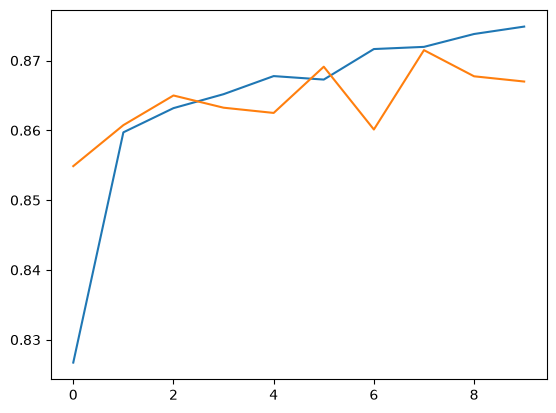

In [89]:
plt.plot(history.history['accuracy'],label='Train')
plt.plot(history.history['val_accuracy'],label='Validation')
plt.show()